| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../11_MACHINE_LEARNING/11_1_Supervised_Learning.ipynb) | [⏩](../11_MACHINE_LEARNING/11_3_Unsupervised_Learning.ipynb) |

# 11.2 Modelos de Machine Learning: sesgo inductivo y comparación justa

**Objetivo del cuaderno.** comparar modelos lineales, vecinos, kernels, árboles y ensambles con un protocolo común y analizar extrapolación

**Antes de empezar:** regresión supervisada, distancia y validación. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report

## 1. Una familia de modelos impone una preferencia

El sesgo inductivo es el conjunto de preferencias que permite generalizar más allá de ejemplos conocidos. Un modelo lineal prefiere relaciones aditivas; vecinos prefiere suavidad local bajo una métrica; un kernel representa similitud; árboles aproximan por regiones; ensambles combinan estimadores.

No hay un ganador universal independiente de la distribución y del criterio de evaluación. La selección requiere definir datos futuros, métrica, coste y restricciones de uso. En SciML importa también si el modelo respeta simetrías, conserva magnitudes o extrapola según una ley conocida.

## 2. Regresión lineal, Ridge y características

La regresión $\hat y=w^Tx+b$ es lineal en sus parámetros. Con características $\phi(x)$ puede representar relaciones no lineales en la entrada, por ejemplo polinomios. Ridge minimiza $\|\Phi w-y\|^2+\alpha\|w\|^2$; reduce la inestabilidad a cambio de sesgo.

Normalizar es esencial cuando la penalización debe tratar componentes comparables. Intercepto y características constantes deben manejarse con cuidado para evitar redundancia. Usamos `include_bias=False` porque el estimador ya ajusta intercepto.

## 3. Vecinos y kernels

k-NN promedia respuestas de los $k$ puntos más cercanos. Con $k$ pequeño puede adaptarse al ruido; con $k$ grande puede borrar variaciones. Su predicción depende mucho de la escala de entradas.

Un SVR con kernel RBF utiliza similitud $K(x,z)=\exp(-\gamma\|x-z\|^2)$. $\gamma$ controla alcance local, $C$ penaliza errores y $\epsilon$ define una banda de insensibilidad. Un kernel no garantiza una extrapolación física; su comportamiento fuera de datos debe comprobarse.

## 4. Árboles y bosques

Un árbol divide el espacio con reglas y predice valores por región. La profundidad controla flexibilidad. Un bosque aleatorio entrena árboles con aleatoriedad de muestras y variables, y promedia. Reduce varianza respecto a un árbol individual en muchos escenarios, aunque puede seguir sesgado.

Los árboles no necesitan normalización para sus particiones usuales, pero tampoco extrapolan tendencias continuas fuera de los valores aprendidos. Importancia predictiva de una variable no demuestra causalidad ni identifica una constante física.

## 5. Datos y conjunto de prueba fijo

Generamos una curva suave $y=\sin(3x)+0.25x$ con ruido. Separar un test al principio evita adaptar cada opción a ese conjunto. Todos los modelos usan los mismos pliegues de validación para reducir variación causada por divisiones distintas.

In [2]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
X=rng.uniform(-2,2,(160,1))
def target_fn(x):return np.sin(3*x)+0.25*x
y=target_fn(X[:,0])+rng.normal(0,0.18,len(X))
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=12)
cv=KFold(n_splits=4,shuffle=True,random_state=13)
candidates={
 'Ridge polinómico':(make_pipeline(PolynomialFeatures(7,include_bias=False),StandardScaler(),Ridge()),{'ridge__alpha':[0.01,0.1,1]}),
 'k-NN':(make_pipeline(StandardScaler(),KNeighborsRegressor()),{'kneighborsregressor__n_neighbors':[3,7,15]}),
 'SVR RBF':(make_pipeline(StandardScaler(),SVR()),{'svr__C':[1,10],'svr__gamma':[0.3,1,3]}),
 'Árbol':(DecisionTreeRegressor(random_state=1),{'max_depth':[2,4,7]}),
 'Bosque':(RandomForestRegressor(n_estimators=70,random_state=1,n_jobs=1),{'min_samples_leaf':[1,3,8]})}
searches={};validation={}
for name,(estimator,grid) in candidates.items():
    search=GridSearchCV(estimator,grid,cv=cv,scoring='neg_mean_squared_error',n_jobs=1)
    search.fit(X_train,y_train);searches[name]=search
    validation[name]=-search.best_score_
    print(name,'MSE CV=',round(validation[name],4),'parámetros=',search.best_params_)
selected=min(validation,key=validation.get)
print('Elección por CV:',selected)

Ridge polinómico MSE CV= 0.0421 parámetros= {'ridge__alpha': 0.01}
k-NN MSE CV= 0.0435 parámetros= {'kneighborsregressor__n_neighbors': 7}
SVR RBF MSE CV= 0.0317 parámetros= {'svr__C': 10, 'svr__gamma': 1}
Árbol MSE CV= 0.0624 parámetros= {'max_depth': 7}
Bosque MSE CV= 0.0445 parámetros= {'min_samples_leaf': 3}
Elección por CV: SVR RBF


## 6. Comparar las predicciones

El gráfico muestra la misma malla, función verdadera y observaciones para todas las familias. La referencia sin ruido sirve para estudiar el mecanismo del modelo; el procedimiento de elección sigue utilizando solo los pliegues de entrenamiento.

`GridSearchCV` reajusta por defecto el mejor candidato sobre todo el conjunto de entrenamiento recibido. No necesita un ajuste manual posterior. Cada pipeline se vuelve a aprender dentro de cada pliegue, evitando fuga por escalado.

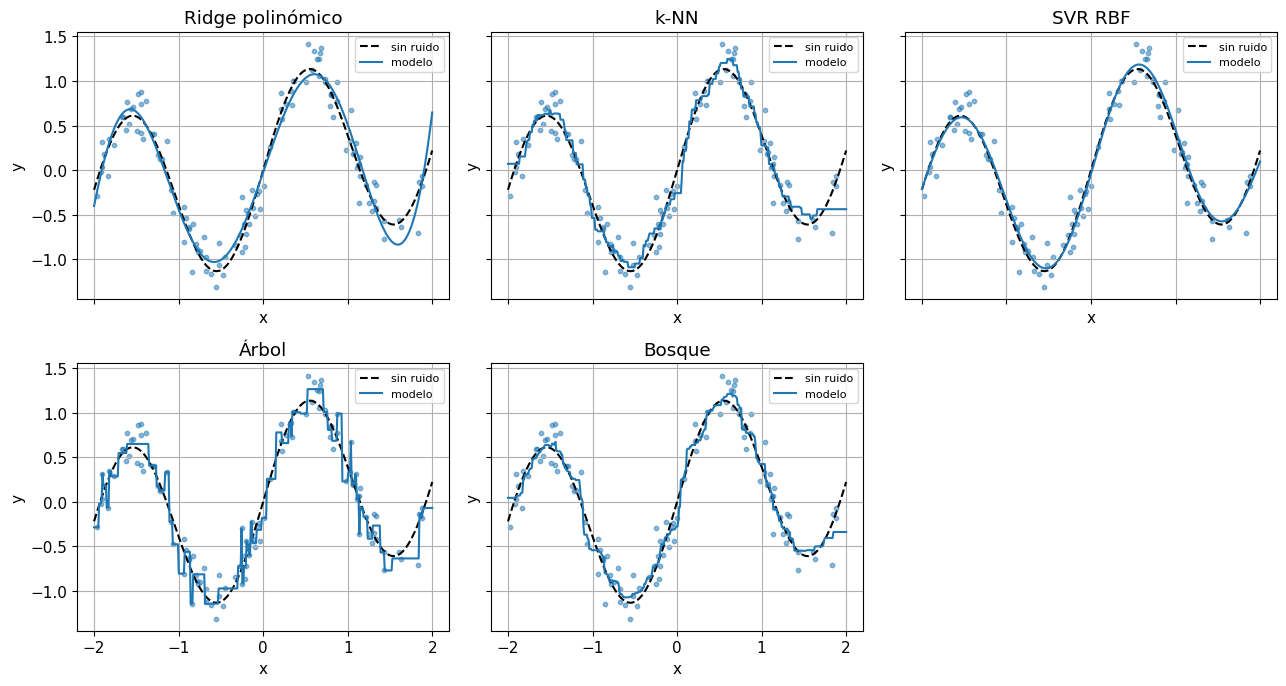

In [3]:
grid=np.linspace(-2,2,400)[:,None]
fig,axes=plt.subplots(2,3,figsize=(13,7),sharex=True,sharey=True)
for ax,(name,search) in zip(axes.ravel(),searches.items()):
    ax.scatter(X_train[:,0],y_train,s=10,alpha=0.5)
    ax.plot(grid[:,0],target_fn(grid[:,0]),'k--',label='sin ruido')
    ax.plot(grid[:,0],search.predict(grid),label='modelo')
    ax.set(title=name,xlabel='x',ylabel='y');ax.legend(fontsize=8)
axes.ravel()[-1].axis('off');plt.tight_layout();plt.show()

**Interpretación.** Los árboles producen escalones; el bosque suaviza mediante promedio sin convertirse en una ley analítica. k-NN crea una aproximación local por promedios y SVR genera una curva dependiente del ancho del kernel. Una curva visualmente atractiva no reemplaza la validación.

## 7. Resultado de test y variación de CV

Evaluamos en prueba únicamente el modelo seleccionado por CV. El resultado es una estimación del rendimiento para puntos independientes en el intervalo $[-2,2]$, con el mismo tipo de ruido. No garantiza la predicción para $x=10$ ni para ruido o régimen diferentes.

Modelo final: SVR RBF
RMSE prueba: 0.21087764434354053
R² prueba: 0.9114184095633248


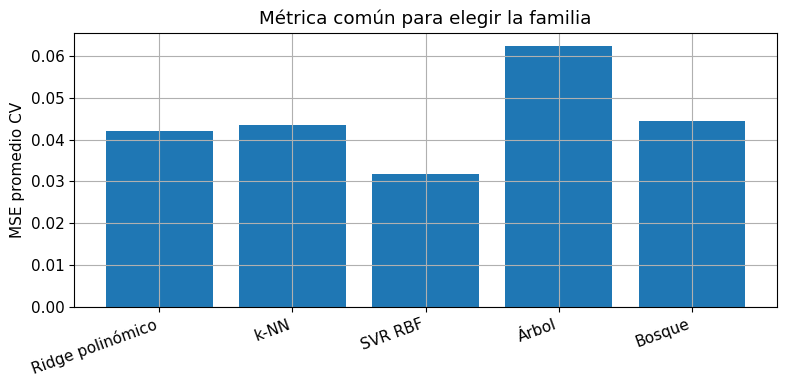

In [4]:
chosen=searches[selected].best_estimator_
pred=chosen.predict(X_test)
print('Modelo final:',selected)
print('RMSE prueba:',np.sqrt(mean_squared_error(y_test,pred)))
print('R² prueba:',r2_score(y_test,pred))
plt.bar(range(len(validation)),list(validation.values()))
plt.xticks(range(len(validation)),list(validation),rotation=20,ha='right')
plt.ylabel('MSE promedio CV');plt.title('Métrica común para elegir la familia');plt.tight_layout();plt.show()
assert np.all(np.isfinite(pred))

## 8. Capacidad del árbol y sobreajuste

Entrenar y validar un árbol con profundidades crecientes ilustra capacidad. El error de entrenamiento suele reducirse al permitir particiones más finas; el error de CV puede empeorar. La profundidad no es la única complejidad: tamaño de hoja, número de variables y ruido también importan.

Este experimento utiliza solo entrenamiento y CV; no vuelve a seleccionar mediante test. En investigaciones con muchas familias y búsquedas conviene validación anidada para estimar el procedimiento completo de selección.

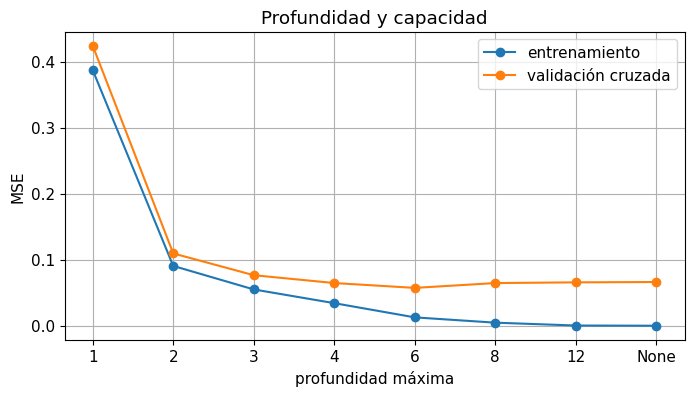

In [5]:
depths=[1,2,3,4,6,8,12,None];train_errors=[];cv_errors=[]
for depth in depths:
    m=DecisionTreeRegressor(max_depth=depth,random_state=2)
    m.fit(X_train,y_train)
    train_errors.append(mean_squared_error(y_train,m.predict(X_train)))
    cv_errors.append(-cross_val_score(m,X_train,y_train,cv=cv,scoring='neg_mean_squared_error').mean())
plt.plot(range(len(depths)),train_errors,'o-',label='entrenamiento')
plt.plot(range(len(depths)),cv_errors,'o-',label='validación cruzada')
plt.xticks(range(len(depths)),[str(d) for d in depths]);plt.xlabel('profundidad máxima');plt.ylabel('MSE')
plt.title('Profundidad y capacidad');plt.legend();plt.show()

## 9. Extrapolar es una pregunta distinta

Después de cerrar la selección, hacemos un diagnóstico independiente fuera del intervalo. Usamos la función sintética para medir error sin reutilizarlo para escoger hiperparámetros. Un polinomio puede crecer muy rápido; un bosque suele mantener respuestas del rango de hojas; un kernel RBF pierde similitud con los datos alejados.

Si se sabe que una respuesta es lineal para temperaturas altas, esa información debe incorporarse en el modelo o validarse con datos de ese régimen. El buen error de interpolación no establece esa propiedad.

In [6]:
outside=np.array([[-3.],[-2.5],[2.5],[3.]])
print('Diagnóstico de comportamiento fuera del dominio:')
print('x:',outside[:,0],'verdad:',target_fn(outside[:,0]))
for name,s in searches.items():print(name,np.round(s.predict(outside),3))

Diagnóstico de comportamiento fuera del dominio:
x: [-3.  -2.5  2.5  3. ] verdad: [-1.16212 -1.563    1.563    1.16212]
Ridge polinómico [21.337 -1.188  5.891  0.575]
k-NN [ 0.071  0.071 -0.438 -0.438]
SVR RBF [-1.393 -1.433  1.018  0.868]
Árbol [-0.288 -0.288 -0.071 -0.071]
Bosque [ 0.043  0.043 -0.34  -0.34 ]


## 10. Interpretabilidad y selección científica

Los coeficientes de un polinomio normalizado corresponden a características transformadas, no directamente a constantes físicas. Un árbol es legible localmente, pero muchos árboles pueden formar una predicción difícil de resumir. Un modelo simple puede ser preferible si su error es comparable y permite comprobaciones analíticas.

En un surrogate de simulación incluye errores máximos, conservación, positividad y tiempo de evaluación además de RMSE. Compara con una referencia elemental: media, ley conocida o interpolación. Si el modelo complejo no supera una referencia relevante, aumentar complejidad puede no estar justificado.

In [7]:
baseline=np.full(len(y_test),np.mean(y_train))
print('RMSE referencia media:',np.sqrt(mean_squared_error(y_test,baseline)))
print('RMSE modelo seleccionado:',np.sqrt(mean_squared_error(y_test,pred)))
print('Máximo error absoluto:',np.max(np.abs(y_test-pred)))

RMSE referencia media: 0.7123565447551553
RMSE modelo seleccionado: 0.21087764434354053
Máximo error absoluto: 0.4521091136942226


## Síntesis y conexión con Scientific Machine Learning

Las familias de modelos expresan supuestos diferentes sobre la relación entrada-salida. Un protocolo común con pipelines y pliegues compartidos hace la comparación interpretable. SciML añade estructura física y suele necesitar evaluar extrapolación a parámetros, tiempos y geometrías nuevos.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../11_MACHINE_LEARNING/11_1_Supervised_Learning.ipynb) | [⏩](../11_MACHINE_LEARNING/11_3_Unsupervised_Learning.ipynb) |